### SOFE4110U Group 16
Titobiloluwa Odufuye [removed]: Part 1, 2, 3 \
Logan Yee [removed]: Part 4, 5 \
João Pedro Minari [removed]: Part 6

# Part 1 — Prepare the real dataset

Use the provided `winequality-red.csv` beside this notebook. It contains
the red-wine measurements and quality scores from the Cortez et al.
Wine Quality dataset. Run the cells from top to bottom.

We remove exact duplicate rows **before** splitting, create three targets
from `quality`, and reuse one stratified split for all tasks. Only training
features are used to fit the scaler; quality scores retain their original units.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 4110
DATA_PATH = Path("winequality-red.csv")

### 1. Inspect the CSV and remove exact duplicates

Detect the delimiter instead of assuming the local CSV uses a particular
separator. Check the schema, numeric types, missing values, and duplicate
rows before preparing any targets or splits.

In [2]:
with DATA_PATH.open(encoding="utf-8-sig", newline="") as csv_file:
    separator = csv.Sniffer().sniff(
        csv_file.read(4096), delimiters=",;\t"
    ).delimiter

raw_df = pd.read_csv(DATA_PATH, sep=separator, encoding="utf-8-sig")
expected_features = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide",
    "density", "pH", "sulphates", "alcohol",
]

print(f"Detected separator: {separator!r}")
print("Column names:", raw_df.columns.tolist())
print("\nColumn data types:")
print(raw_df.dtypes.to_string())
print("\nMissing values per column:")
print(raw_df.isna().sum().to_string())

assert raw_df.columns.tolist() == expected_features + ["quality"], "Unexpected CSV columns."
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in raw_df.dtypes)
assert not raw_df.isna().any().any(), "Resolve missing values before proceeding."
assert np.isfinite(raw_df.to_numpy()).all(), "The CSV contains non-finite values."

rows_before = len(raw_df)
duplicate_count = int(raw_df.duplicated().sum())
df = raw_df.drop_duplicates().reset_index(drop=True)
print(f"\nRows before duplicate removal: {rows_before:,}")
print(f"Exact duplicate rows removed: {duplicate_count:,}")
print(f"Rows after duplicate removal: {len(df):,}")

Detected separator: ','
Column names: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Column data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0

Rows before duplicate removal: 1,5

### 2. Separate the 11 input features and create the targets

Targets are kept in a separate table so that neither `quality` nor a
target derived from it enters the input matrix.

| Task | Target | Required model output |
| --- | --- | --- |
| Regression | Original quality score | One predicted mean |
| Binary | 0 for quality < 6; 1 for quality ≥ 6 | One logit |
| Multiclass | 0 for quality ≤ 5; 1 for quality = 6; 2 for quality ≥ 7 | Three logits |

Input features (11):
 1. fixed acidity
 2. volatile acidity
 3. citric acid
 4. residual sugar
 5. chlorides
 6. free sulfur dioxide
 7. total sulfur dioxide
 8. density
 9. pH
10. sulphates
11. alcohol

Quality score distribution:
         original_rows  deduplicated_rows
quality                                  
3                   10                 10
4                   53                 53
5                  681                577
6                  638                535
7                  199                167
8                   18                 17


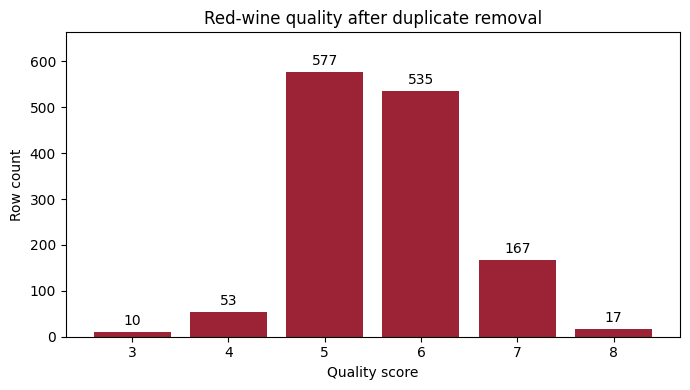

In [3]:
X = df.drop(columns="quality").copy()
feature_names = X.columns.tolist()
quality = df["quality"].copy()

targets = pd.DataFrame({
    "regression": quality,
    "binary": (quality >= 6).astype(np.int64),
    "multiclass": np.select(
        [quality <= 5, quality == 6, quality >= 7],
        [0, 1, 2],
        default=-1,
    ).astype(np.int64),
}, index=df.index)

assert X.shape[1] == 11
assert feature_names == expected_features
assert (targets["multiclass"] >= 0).all(), "An unexpected score has no class."
print(f"Input features ({len(feature_names)}):")
for number, name in enumerate(feature_names, start=1):
    print(f"{number:2}. {name}")

score_distribution = pd.DataFrame({
    "original_rows": raw_df["quality"].value_counts(),
    "deduplicated_rows": quality.value_counts(),
}).fillna(0).astype(int).sort_index()
score_distribution.index.name = "quality"
print("\nQuality score distribution:")
print(score_distribution.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    score_distribution.index.astype(str),
    score_distribution["deduplicated_rows"],
    color="#9b2335",
)
ax.set(title="Red-wine quality after duplicate removal", xlabel="Quality score", ylabel="Row count")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

### 3. Reuse one 60% / 20% / 20% split for every task

First hold out 20% of the row indices for testing. Then hold out 25% of
the remaining indices for validation. Both calls use `random_state=4110`
and stratify by the three-class target. Integer rounding determines the
final split sizes. These indices refer to the deduplicated dataframe.

In [4]:
row_indices = np.arange(len(df))
multiclass_target = targets["multiclass"].to_numpy()

train_val_idx, test_idx = train_test_split(
    row_indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=multiclass_target,
)
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=multiclass_target[train_val_idx],
)
split_indices = {"train": train_idx, "validation": val_idx, "test": test_idx}

split_sizes = pd.DataFrame({
    "rows": {name: len(indices) for name, indices in split_indices.items()}
})
split_sizes["percent"] = 100 * split_sizes["rows"] / len(df)
print("Split sizes:")
print(split_sizes.to_string(float_format=lambda value: f"{value:.2f}"))

for task, classes in (("binary", [0, 1]), ("multiclass", [0, 1, 2])):
    class_counts = pd.DataFrame({
        split: targets[task].iloc[indices].value_counts().reindex(classes, fill_value=0)
        for split, indices in split_indices.items()
        if split in ("train", "validation")
    })
    class_counts.index.name = "class"
    print(f"\n{task.capitalize()} class counts:")
    print(class_counts.to_string())

Split sizes:
            rows  percent
train        815    59.97
validation   272    20.01
test         272    20.01

Binary class counts:
       train  validation
class                   
0        384         128
1        431         144

Multiclass class counts:
       train  validation
class                   
0        384         128
1        321         107
2        110          37


### 4. Standardize inputs using training statistics only

Fit `StandardScaler` on the training feature rows, and use that fitted
scaler to transform all three sets. Do not standardize any target.

In [5]:
scaler = StandardScaler()
scaler.fit(X.iloc[train_idx])
X_scaled = {
    split: scaler.transform(X.iloc[indices]).astype(np.float32)
    for split, indices in split_indices.items()
}

print(f"Scaler fitted on {scaler.n_samples_seen_} training rows only.")
print("Maximum absolute training feature mean:", np.abs(X_scaled["train"].mean(axis=0)).max())
print("Training feature standard deviations:")
print(np.round(X_scaled["train"].std(axis=0), 6))

Scaler fitted on 815 training rows only.
Maximum absolute training feature mean: 1.1701525e-08
Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 5. Build PyTorch tensors

`data[split]` holds the shared inputs and all three aligned targets.
Inputs have shape `(N, 11)` and dtype `torch.float32`. Regression and
binary targets have shape `(N, 1)` and dtype `torch.float32`.
Multiclass targets have shape `(N,)` and dtype `torch.long` (displayed
by PyTorch as `torch.int64`).

In [6]:
data = {}
for split, indices in split_indices.items():
    split_targets = targets.iloc[indices]
    data[split] = {
        "X": torch.from_numpy(X_scaled[split]),
        "y_regression": torch.from_numpy(
            split_targets["regression"].to_numpy(dtype=np.float32).reshape(-1, 1)
        ),
        "y_binary": torch.from_numpy(
            split_targets["binary"].to_numpy(dtype=np.float32).reshape(-1, 1)
        ),
        "y_multiclass": torch.from_numpy(
            split_targets["multiclass"].to_numpy(dtype=np.int64)
        ),
    }

tensor_summary = pd.DataFrame([
    {"split": split, "tensor": name, "shape": tuple(tensor.shape), "dtype": str(tensor.dtype)}
    for split, tensors in data.items()
    for name, tensor in tensors.items()
])
print(tensor_summary.to_string(index=False))

     split       tensor     shape         dtype
     train            X (815, 11) torch.float32
     train y_regression  (815, 1) torch.float32
     train     y_binary  (815, 1) torch.float32
     train y_multiclass    (815,)   torch.int64
validation            X (272, 11) torch.float32
validation y_regression  (272, 1) torch.float32
validation     y_binary  (272, 1) torch.float32
validation y_multiclass    (272,)   torch.int64
      test            X (272, 11) torch.float32
      test y_regression  (272, 1) torch.float32
      test     y_binary  (272, 1) torch.float32
      test y_multiclass    (272,)   torch.int64


### 6. Verify the preparation

Check that the splits cover every deduplicated row exactly once, the
scaler uses training statistics, and each task has correctly aligned
targets, shapes, and dtypes. These checks also confirm that regression
targets still contain the original quality scores.

In [7]:
assert not df.duplicated().any()
assert rows_before - len(df) == duplicate_count
combined_indices = np.concatenate(list(split_indices.values()))
np.testing.assert_array_equal(np.sort(combined_indices), row_indices)

assert scaler.n_samples_seen_ == len(train_idx)
np.testing.assert_allclose(scaler.mean_, X.iloc[train_idx].mean(axis=0))
np.testing.assert_allclose(scaler.var_, X.iloc[train_idx].var(axis=0, ddof=0))
np.testing.assert_allclose(X_scaled["train"].mean(axis=0), 0.0, atol=1e-6)
np.testing.assert_allclose(X_scaled["train"].std(axis=0), 1.0, atol=1e-6)

for split, indices in split_indices.items():
    tensors = data[split]
    n = len(indices)
    assert tensors["X"].shape == (n, 11)
    assert tensors["X"].dtype == torch.float32
    assert torch.isfinite(tensors["X"]).all()
    for target in ("y_regression", "y_binary"):
        assert tensors[target].shape == (n, 1)
        assert tensors[target].dtype == torch.float32
    assert tensors["y_multiclass"].shape == (n,)
    assert tensors["y_multiclass"].dtype == torch.long

    expected_quality = quality.iloc[indices].to_numpy(dtype=np.float32)
    np.testing.assert_array_equal(tensors["y_regression"].numpy().ravel(), expected_quality)
    np.testing.assert_array_equal(tensors["y_binary"].numpy().ravel(), expected_quality >= 6)
    expected_classes = np.where(expected_quality <= 5, 0, np.where(expected_quality == 6, 1, 2))
    np.testing.assert_array_equal(tensors["y_multiclass"].numpy(), expected_classes)
    np.testing.assert_allclose(
        scaler.inverse_transform(tensors["X"].numpy()),
        X.iloc[indices].to_numpy(),
        rtol=1e-5,
        atol=1e-5,
    )

print("All Part 1 checks passed.")
print("Ready for later parts: data, split_indices, feature_names, and scaler.")

All Part 1 checks passed.
Ready for later parts: data, split_indices, feature_names, and scaler.


# Part 2 — Check the loss functions

These examples use the supplied predictions, **not a trained network**.
All logarithms are natural and aggregate losses use mean reduction.
Values below are rounded; the code verifies them with float32 tensors
and a tolerance of $10^{-6}$.

### A. Regression and Gaussian negative log likelihood

With targets $y=[5,6,8]$ and means $\mu=[4.5,6.5,7]$,

$$
(y-\mu)^2=[(5-4.5)^2,(6-6.5)^2,(8-7)^2]=[0.25,0.25,1],
\qquad \mathrm{MSE}=\frac{0.25+0.25+1}{3}=0.5.
$$

For variance $v>0$, the **full** Gaussian NLL for example $i$ is

$$
\ell_i=\frac12\left[\log(2\pi v)+\frac{(y_i-\mu_i)^2}{v}\right].
$$

| Variance | Constant $\frac12\log(2\pi v)$ | NLL for $y=5$ | NLL for $y=6$ | NLL for $y=8$ | Mean NLL |
| --- | ---: | ---: | ---: | ---: | ---: |
| 1 | 0.918938533 | 1.043938533 | 1.043938533 | 1.418938533 | **1.168938533** |
| 0.25 | 0.225791353 | 0.725791353 | 0.725791353 | 2.225791353 | **1.225791353** |

For $v=1$, add half of each squared error to 0.918938533.
For $v=0.25$, add twice each squared error to 0.225791353.

In [8]:
import math
from torch import nn
from IPython.display import Markdown, display

example_y = torch.tensor([[5.0], [6.0], [8.0]], dtype=torch.float32)
example_mu = torch.tensor([[4.5], [6.5], [7.0]], dtype=torch.float32)
assert example_y.shape == example_mu.shape == (3, 1)
squared_errors = (example_y - example_mu).square()
torch.testing.assert_close(squared_errors, torch.tensor([[0.25], [0.25], [1.0]]))
mse_check = nn.MSELoss(reduction="mean")(example_mu, example_y)
torch.testing.assert_close(mse_check, torch.tensor(0.5))

gaussian_rows = []
gaussian_expected = {
    1.0: [1.043938533, 1.043938533, 1.418938533],
    0.25: [0.725791353, 0.725791353, 2.225791353],
}
for variance in (1.0, 0.25):
    variance_tensor = torch.full_like(example_mu, variance)
    manual_nll = 0.5 * (
        torch.log(2 * math.pi * variance_tensor)
        + squared_errors / variance_tensor
    )
    torch_nll = nn.GaussianNLLLoss(full=True, reduction="none")(
        example_mu, example_y, variance_tensor
    )
    mean_nll = nn.GaussianNLLLoss(full=True, reduction="mean")(
        example_mu, example_y, variance_tensor
    )
    expected = torch.tensor(gaussian_expected[variance]).reshape(3, 1)
    torch.testing.assert_close(torch_nll, expected, atol=1e-6, rtol=1e-6)
    torch.testing.assert_close(torch_nll, manual_nll, atol=1e-6, rtol=1e-6)
    torch.testing.assert_close(mean_nll, expected.mean(), atol=1e-6, rtol=1e-6)
    gaussian_rows.append({
        "variance": variance,
        "NLL example 1": torch_nll[0].item(),
        "NLL example 2": torch_nll[1].item(),
        "NLL example 3": torch_nll[2].item(),
        "mean NLL": mean_nll.item(),
    })
print("Squared errors:", squared_errors.flatten().tolist())
print(f"nn.MSELoss = {mse_check.item():.6f}")
display(pd.DataFrame(gaussian_rows).round(6))

Squared errors: [0.25, 0.25, 1.0]
nn.MSELoss = 0.500000


,variance,NLL example 1,NLL example 2,NLL example 3,mean NLL
0,1.00,1.043939,1.043939,1.418939,1.168939
1,0.25,0.725791,0.725791,2.225791,1.225791


For a **fixed, shared positive variance**, mean Gaussian NLL satisfies

$$
\overline{\ell}_{\mathrm{Gaussian}}
=\frac12\log(2\pi v)+\frac{\mathrm{MSE}}{2v}.
$$

This is a positive affine transformation of MSE, so it ranks mean
predictions in the same order when variance is held fixed. Their values
differ by the offset and scale, and their gradients with respect to the
means obey
$\nabla_\mu\overline{\ell}_{\mathrm{Gaussian}}
=\frac{1}{2v}\nabla_\mu\mathrm{MSE}$.
The gradient factor is 0.5 for $v=1$ and 2 for $v=0.25$.
This equivalence does not generally hold when models predict different
variances. **full=True** includes the otherwise omitted
$\frac12\log(2\pi)$ term in each example's NLL.

Wine scores are discrete, ordered ratings with a bounded range. A
Gaussian describes a continuous, unbounded numerical quantity, so it
approximates the scores and treats numerical differences between ratings
as meaningful. Its density at a point is not the probability of that
exact class; probabilities come from integrating density over an interval,
and density itself may exceed 1.

A full Gaussian NLL **can be negative**. At $y=\mu$ and $v=0.01$,
$\ell=\frac12\log(2\pi\cdot0.01)=-1.383646560$.
This corresponds to density greater than 1, not a class probability
greater than 1.

### B. Binary cross entropy

For logit $z$, $p=\sigma(z)=1/(1+e^{-z})$. With targets
$[0,1,0]$, the loss is
$\ell=-[y\log p+(1-y)\log(1-p)]$.

| Logit $z$ | Target $y$ | $p(y=1)$ | BCE calculation | BCE |
| ---: | ---: | ---: | --- | ---: |
| -2 | 0 | 0.119202922 | $-\log(0.880797078)$ | 0.126928011 |
| 0 | 1 | 0.500000000 | $-\log(0.5)$ | 0.693147181 |
| 2 | 0 | 0.880797078 | $-\log(0.119202922)$ | 2.126928011 |

$$
\mathrm{mean\ BCE}
=\frac{0.126928011+0.693147181+2.126928011}{3}
=\boxed{0.982334401}.
$$

**BCELoss** on sigmoid probabilities and **BCEWithLogitsLoss** on the
original logits represent the same Bernoulli NLL. The logits version
combines the operations using a stable expression,
$\max(z,0)-zy+\log(1+e^{-|z|})$, avoiding explicit logarithms of
probabilities that can round to zero. It is preferred for training.

In [9]:
binary_logits_example = torch.tensor([[-2.0], [0.0], [2.0]], dtype=torch.float32)
binary_y_example = torch.tensor([[0.0], [1.0], [0.0]], dtype=torch.float32)
assert binary_logits_example.shape == binary_y_example.shape == (3, 1)
binary_probabilities = torch.sigmoid(binary_logits_example)
manual_bce = -(
    binary_y_example * torch.log(binary_probabilities)
    + (1 - binary_y_example) * torch.log1p(-binary_probabilities)
)
bce_probabilities = nn.BCELoss(reduction="mean")(binary_probabilities, binary_y_example)
bce_logits = nn.BCEWithLogitsLoss(reduction="mean")(
    binary_logits_example, binary_y_example
)
expected_bce = torch.tensor([[0.126928011], [0.693147181], [2.126928011]])
torch.testing.assert_close(manual_bce, expected_bce, atol=1e-6, rtol=1e-6)
torch.testing.assert_close(bce_probabilities, expected_bce.mean(), atol=1e-6, rtol=1e-6)
torch.testing.assert_close(bce_logits, expected_bce.mean(), atol=1e-6, rtol=1e-6)
display(pd.DataFrame({
    "logit": binary_logits_example.flatten().numpy(),
    "target": binary_y_example.flatten().numpy(),
    "probability class 1": binary_probabilities.flatten().numpy(),
    "BCE": manual_bce.flatten().numpy(),
}).round(6))
print(f"BCELoss on probabilities: {bce_probabilities.item():.6f}")
print(f"BCEWithLogitsLoss on logits: {bce_logits.item():.6f}")

confident_logits = torch.tensor([[2.0], [8.0]])
zero_targets = torch.zeros_like(confident_logits)
confident_losses = nn.BCEWithLogitsLoss(reduction="none")(confident_logits, zero_targets)
torch.testing.assert_close(
    confident_losses, torch.tensor([[2.126928011], [8.000335406]]),
    atol=1e-6, rtol=1e-6,
)
display(pd.DataFrame({
    "logit": confident_logits.flatten().numpy(),
    "probability class 1": torch.sigmoid(confident_logits).flatten().numpy(),
    "target": zero_targets.flatten().numpy(),
    "BCE": confident_losses.flatten().numpy(),
}).round(6))

,logit,target,probability class 1,BCE
0,-2.0,0.0,0.119203,0.126928
1,0.0,1.0,0.500000,0.693147
2,2.0,0.0,0.880797,2.126928


BCELoss on probabilities: 0.982334
BCEWithLogitsLoss on logits: 0.982334


,logit,probability class 1,target,BCE
0,2.0,0.880797,0.0,2.126928
1,8.0,0.999665,0.0,8.000336


For target 0, the loss is $\log(1+e^z)$: it increases from
**2.126928011** at $z=2$ to **8.000335406** at $z=8$.
The second prediction assigns probability 0.999664650 to class 1,
compared with 0.880797078 for the first. It is more confident in the
**wrong** class, so BCE penalizes it more strongly even though both
predictions would have the same classification error.

Applying sigmoid before **BCEWithLogitsLoss** is an error: the loss
interprets the supplied probability as a new logit, effectively using
$\sigma(\sigma(z))$ as the class-1 probability. Its range is only
approximately $(0.5,0.7311)$, instead of $(0,1)$, and the extra
sigmoid also attenuates gradients. Pass raw logits directly.

### C. Multiclass cross entropy and NLLLoss

Softmax gives $p_k=e^{z_k}/\sum_j e^{z_j}$.

* For $[2,0,-1]$, the denominator is $e^2+1+e^{-1}$.
  The probabilities are
  $[0.843794734,\ 0.114195199,\ 0.042010066]$.
* For $[0,1,3]$, the denominator is $1+e+e^3$.
  The probabilities are
  $[0.042010066,\ 0.114195199,\ 0.843794734]$.

The correct class is 2 for the first row and 0 for the second, so each
receives probability **0.042010066**. Each negative log probability is

$$
-\log(0.04201006613406605)=3.169846020,
\qquad \mathrm{mean\ NLL}=\boxed{3.169846020}.
$$

For class index $y$, both implementations calculate
$-\log p_y=-z_y+\log\sum_j e^{z_j}$.
**CrossEntropyLoss** accepts raw logits and combines log-softmax with
NLL. **NLLLoss** expects log probabilities and simply selects and negates
the correct entry, so raw logits or ordinary probabilities would give
the wrong objective. Using **log_softmax** directly is more stable than
taking the logarithm of separately computed softmax probabilities.
The assignment's MLPs therefore pass raw logits to CrossEntropyLoss.

In [10]:
multiclass_logits_example = torch.tensor(
    [[2.0, 0.0, -1.0], [0.0, 1.0, 3.0]], dtype=torch.float32
)
multiclass_y_example = torch.tensor([2, 0], dtype=torch.long)
multiclass_probabilities = torch.softmax(multiclass_logits_example, dim=1)
correct_probabilities = multiclass_probabilities[
    torch.arange(len(multiclass_y_example)), multiclass_y_example
]
individual_nll = -torch.log(correct_probabilities)
ce_check = nn.CrossEntropyLoss(reduction="mean")(
    multiclass_logits_example, multiclass_y_example
)
categorical_nll_check = nn.NLLLoss(reduction="mean")(
    torch.log_softmax(multiclass_logits_example, dim=1), multiclass_y_example,
)
expected_probabilities = torch.tensor([
    [0.843794734, 0.114195199, 0.042010066],
    [0.042010066, 0.114195199, 0.843794734],
])
torch.testing.assert_close(
    multiclass_probabilities, expected_probabilities, atol=1e-6, rtol=1e-6
)
expected_ce = torch.tensor(3.169846020)
torch.testing.assert_close(individual_nll, expected_ce.expand(2), atol=1e-6, rtol=1e-6)
torch.testing.assert_close(ce_check, expected_ce, atol=1e-6, rtol=1e-6)
torch.testing.assert_close(categorical_nll_check, expected_ce, atol=1e-6, rtol=1e-6)
display(pd.DataFrame({
    "p(class 0)": multiclass_probabilities[:, 0].numpy(),
    "p(class 1)": multiclass_probabilities[:, 1].numpy(),
    "p(class 2)": multiclass_probabilities[:, 2].numpy(),
    "correct class": multiclass_y_example.numpy(),
    "correct-class probability": correct_probabilities.numpy(),
    "negative log probability": individual_nll.numpy(),
}).round(6))
print(f"CrossEntropyLoss on logits: {ce_check.item():.6f}")
print(f"NLLLoss on log_softmax: {categorical_nll_check.item():.6f}")
print("All Part 2 numerical checks passed.")

,p(class 0),p(class 1),p(class 2),correct class,correct-class probability,negative log probability
0,0.843795,0.114195,0.042010,2,0.04201,3.169846
1,0.042010,0.114195,0.843795,0,0.04201,3.169846


CrossEntropyLoss on logits: 3.169846
NLLLoss on log_softmax: 3.169846
All Part 2 numerical checks passed.


## Distribution comparison

| Distribution | Target type | Parameters represented by the network | Final prediction |
| --- | --- | --- | --- |
| Gaussian | A numerical value; an approximation for ordered wine ratings | Mean $\mu$, with a fixed positive variance for MSE; a learned-variance model also predicts a value transformed to positive variance $v$ | Use $\mu$ as the score prediction; $v$ describes uncertainty |
| Bernoulli | A binary label, 0 or 1 | One raw logit $z$, transformed to $p=\sigma(z)$ when a probability is needed | Predict class 1 when $p\geq0.5$, otherwise class 0 |
| Categorical | One integer class index from 0 to $K-1$ | $K$ raw logits, transformed to a probability vector with softmax when needed | Choose the largest logit (equivalently the largest probability) |

The regression output remains a numerical mean. Binary and multiclass
training use logits directly; probability transformations are used only
where the loss or evaluation requires them.

# Part 3 — Build MLPs and apply grid search

## Grid chosen before running experiments

| Setting | Fixed choices |
| --- | --- |
| Hidden layers | **1, 2** |
| Width of every hidden layer | **32, 64** |
| Learning rate | **0.001, 0.003** |
| Optimizer | Adam, all settings other than learning rate at defaults |
| Batch size | 64 |
| Epochs per candidate | 100 |
| Seed before every candidate | 4110 |

One versus two hidden layers compares a shallow model with a deeper
model. Widths 32 and 64 compare two modest capacities on the 815 training
examples. Learning rates 0.001 and 0.003 provide a conservative baseline
and a faster alternative. These choices are fixed before inspecting
experiment results and are reused for all tasks.

**ParameterGrid** enumerates $2\times2\times2=8$ candidates per task,
giving **24 independent training runs**. Depth, width, and learning rate
are chosen outside gradient descent; Adam updates the weights and biases
within each candidate. Every candidate trains for all 100 epochs, while
its best validation epoch is retained separately. The test set is not
evaluated or used to choose settings or epochs.

In [11]:
import copy
import json
import platform
import sklearn
from sklearn.model_selection import ParameterGrid
from torch.utils.data import DataLoader, TensorDataset

# These small networks run efficiently and reproducibly on one CPU thread.
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cpu")
EPOCHS = 100
BATCH_SIZE = 64
PARAM_GRID = {
    "depth": [1, 2],
    "width": [32, 64],
    "learning_rate": [0.001, 0.003],
}
grid_candidates = list(ParameterGrid(PARAM_GRID))
assert len(grid_candidates) == 8
TASKS = {
    "regression": {
        "target": "y_regression", "output_dim": 1,
        "loss_factory": nn.MSELoss, "label": "MSE regression",
    },
    "binary": {
        "target": "y_binary", "output_dim": 1,
        "loss_factory": nn.BCEWithLogitsLoss, "label": "Binary classification",
    },
    "multiclass": {
        "target": "y_multiclass", "output_dim": 3,
        "loss_factory": nn.CrossEntropyLoss, "label": "Multiclass classification",
    },
}
RESULTS_DIR = Path("results") / "part3"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
experiment_config = {
    "grid": PARAM_GRID, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
    "seed": RANDOM_STATE, "optimizer": "Adam (other settings at defaults)",
    "device": str(DEVICE), "torch": torch.__version__,
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
    "training_rows": len(train_idx), "validation_rows": len(val_idx),
}
(RESULTS_DIR / "experiment_config.json").write_text(
    json.dumps(experiment_config, indent=2) + "\n"
)
display(pd.DataFrame(grid_candidates))
print(f"Planned runs: {len(grid_candidates)} x {len(TASKS)} = 24; {EPOCHS} epochs each.")

,depth,learning_rate,width
0,1,0.001,32
1,1,0.001,64
2,1,0.003,32
3,1,0.003,64
4,2,0.001,32
5,2,0.001,64
6,2,0.003,32
7,2,0.003,64


Planned runs: 8 x 3 = 24; 100 epochs each.


### Reusable MLP builder and training loop

Each hidden layer is **Linear → ReLU**, with the same width throughout
a candidate. A final Linear layer has no activation: it produces one
unrestricted mean, one binary logit, or three class logits.

Each candidate receives a fresh model, optimizer, and shuffled training
loader after resetting the seed. A separately seeded loader generator
makes the training-row order reproducible across candidates. Training
evaluation and validation loaders do not shuffle.

After every epoch, losses are recomputed on the **entire** training and
validation sets in evaluation mode under no_grad. Batch-mean losses are
weighted by batch size, including the smaller last batch. These are
losses at the epoch's final weights, not averages from changing weights
during optimization. A deep copy preserves the best validation weights
independently of subsequent updates.

In [12]:
def build_mlp(depth, width, output_dim):
    "11 inputs, a fixed-width stack of hidden layers, and raw outputs."
    layers = []
    input_dim = 11
    for _ in range(depth):
        layers.extend([nn.Linear(input_dim, width), nn.ReLU()])
        input_dim = width
    layers.append(nn.Linear(input_dim, output_dim))
    return nn.Sequential(*layers)


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def mean_loss(model, loader, criterion):
    "Example-weighted full-set loss; evaluation does not track gradients."
    model.eval()
    loss_sum = 0.0
    example_count = 0
    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
            batch_mean = criterion(model(batch_X), batch_y)
            loss_sum += batch_mean.item() * len(batch_X)
            example_count += len(batch_X)
    return loss_sum / example_count


def train_candidate(config, output_dim, criterion, train_data, validation_data):
    torch.manual_seed(RANDOM_STATE)
    model = build_mlp(config["depth"], config["width"], output_dim).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    shuffle_generator = torch.Generator().manual_seed(RANDOM_STATE)
    train_loader = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True,
        generator=shuffle_generator, num_workers=0,
    )
    train_eval_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=False)
    validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False)
    history = []
    best_validation_loss = float("inf")
    best_state = None
    selected_epoch = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite training loss for {config}, epoch {epoch}.")
            loss.backward()
            optimizer.step()

        training_loss = mean_loss(model, train_eval_loader, criterion)
        validation_loss = mean_loss(model, validation_loader, criterion)
        if not (math.isfinite(training_loss) and math.isfinite(validation_loss)):
            raise RuntimeError(f"Non-finite epoch loss for {config}, epoch {epoch}.")
        history.append({
            "epoch": epoch,
            "training_loss": training_loss,
            "validation_loss": validation_loss,
        })
        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            selected_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        model.train()

    selected_record = history[selected_epoch - 1]
    return {
        "config": dict(config),
        "parameter_count": count_parameters(model),
        "selected_epoch": selected_epoch,
        "training_loss": selected_record["training_loss"],
        "validation_loss": best_validation_loss,
        "state_dict": best_state,
        "history": history,
    }

### Run the three grids

The loop below passes only the training and validation tensors to the
training function. Losses are unweighted: MSELoss, BCEWithLogitsLoss, and
CrossEntropyLoss, all with mean reduction. Each of the 24 runs uses a
fresh instance of its task's loss and the same fixed training budget.

In [13]:
runs_by_task = {}
for task, spec in TASKS.items():
    train_dataset = TensorDataset(data["train"]["X"], data["train"][spec["target"]])
    validation_dataset = TensorDataset(
        data["validation"]["X"], data["validation"][spec["target"]]
    )
    task_runs = []
    for candidate_id, config in enumerate(grid_candidates, start=1):
        result = train_candidate(
            config=config,
            output_dim=spec["output_dim"],
            criterion=spec["loss_factory"](reduction="mean"),
            train_data=train_dataset,
            validation_data=validation_dataset,
        )
        result["candidate_id"] = candidate_id
        task_runs.append(result)
        print(
            f"{task:10s} {candidate_id}/8 | depth={config['depth']}, "
            f"width={config['width']}, lr={config['learning_rate']:.3f} | "
            f"best epoch={result['selected_epoch']:3d}, "
            f"validation loss={result['validation_loss']:.6f}",
            flush=True,
        )
    runs_by_task[task] = task_runs
print("Completed all 24 runs, each with 100 epochs.")

regression 1/8 | depth=1, width=32, lr=0.001 | best epoch=100, validation loss=0.628483
regression 2/8 | depth=1, width=64, lr=0.001 | best epoch=100, validation loss=0.597023
regression 3/8 | depth=1, width=32, lr=0.003 | best epoch= 98, validation loss=0.457242
regression 4/8 | depth=1, width=64, lr=0.003 | best epoch= 77, validation loss=0.426866
regression 5/8 | depth=2, width=32, lr=0.001 | best epoch= 98, validation loss=0.459054
regression 6/8 | depth=2, width=64, lr=0.001 | best epoch= 66, validation loss=0.394579
regression 7/8 | depth=2, width=32, lr=0.003 | best epoch= 77, validation loss=0.383229
regression 8/8 | depth=2, width=64, lr=0.003 | best epoch= 30, validation loss=0.388367
binary     1/8 | depth=1, width=32, lr=0.001 | best epoch= 95, validation loss=0.444196
binary     2/8 | depth=1, width=64, lr=0.001 | best epoch= 95, validation loss=0.440750
binary     3/8 | depth=1, width=32, lr=0.003 | best epoch= 34, validation loss=0.440072
binary     4/8 | depth=1, width=

### Rank candidates and retain the selected weights

Candidates are ranked by their lowest validation loss. Exact ties are
broken by fewer trainable parameters; candidate order resolves any
remaining tie. Within a run, the first epoch achieving its minimum is
retained. The training loss in each table is measured at that same
selected epoch. Printed losses are rounded, but selection uses full
precision.

The three selected models and their checkpoints retain those exact
weights. There is no retraining on training plus validation data.
The selected MSE model is also retained as **best_mse_model** for Part 4.

In [14]:
def ranking_key(run):
    return (run["validation_loss"], run["parameter_count"], run["candidate_id"])


results_tables = {}
best_runs = {}
selected_models = {}
selection_metadata = {}

for task, spec in TASKS.items():
    ranked = sorted(runs_by_task[task], key=ranking_key)
    table = pd.DataFrame([
        {
            "candidate": run["candidate_id"],
            "depth": run["config"]["depth"],
            "width": run["config"]["width"],
            "learning_rate": run["config"]["learning_rate"],
            "parameter_count": run["parameter_count"],
            "selected_epoch": run["selected_epoch"],
            "training_loss": run["training_loss"],
            "validation_loss": run["validation_loss"],
        }
        for run in ranked
    ])
    table.index = np.arange(1, len(table) + 1)
    table.index.name = "rank"
    results_tables[task] = table
    display(Markdown(f"### {spec['label']} — eight candidates"))
    display(table.round(6))
    table.to_csv(RESULTS_DIR / f"{task}_results.csv")

    histories = pd.DataFrame([
        {"candidate": run["candidate_id"], **run["config"], **epoch_record}
        for run in runs_by_task[task]
        for epoch_record in run["history"]
    ])
    histories.to_csv(RESULTS_DIR / f"{task}_histories.csv", index=False)

    best = ranked[0]
    best_runs[task] = best
    selected_model = build_mlp(
        best["config"]["depth"], best["config"]["width"], spec["output_dim"]
    ).to(DEVICE)
    selected_model.load_state_dict(best["state_dict"])
    selected_model.eval()
    selected_models[task] = selected_model
    metadata = {
        "task": task, **best["config"],
        "output_dim": spec["output_dim"],
        "parameter_count": best["parameter_count"],
        "selected_epoch": best["selected_epoch"],
        "training_loss": best["training_loss"],
        "validation_loss": best["validation_loss"],
        "seed": RANDOM_STATE,
    }
    selection_metadata[task] = metadata
    torch.save(
        {"state_dict": best["state_dict"], **metadata},
        RESULTS_DIR / f"best_{task}.pt",
    )

(RESULTS_DIR / "selected_models.json").write_text(
    json.dumps(selection_metadata, indent=2) + "\n"
)
best_mse_model = selected_models["regression"]
best_mse_config = dict(best_runs["regression"]["config"])
best_mse_epoch = best_runs["regression"]["selected_epoch"]
print("Saved the three selected checkpoints, ranked tables, and all epoch histories.")

### MSE regression — eight candidates

,candidate,depth,width,learning_rate,parameter_count,selected_epoch,training_loss,validation_loss
rank,,,,,,,,
1,7,2,32,0.003,1473,77,0.367017,0.383229
2,8,2,64,0.003,4993,30,0.382132,0.388367
3,6,2,64,0.001,4993,66,0.364794,0.394579
4,4,1,64,0.003,833,77,0.359079,0.426866
5,3,1,32,0.003,417,98,0.399813,0.457242
6,5,2,32,0.001,1473,98,0.405161,0.459054
7,2,1,64,0.001,833,100,0.548981,0.597023
8,1,1,32,0.001,417,100,0.631744,0.628483


### Binary classification — eight candidates

,candidate,depth,width,learning_rate,parameter_count,selected_epoch,training_loss,validation_loss
rank,,,,,,,,
1,4,1,64,0.003,833,49,0.459903,0.436369
2,8,2,64,0.003,4993,18,0.449821,0.437874
3,3,1,32,0.003,417,34,0.486248,0.440072
4,2,1,64,0.001,833,95,0.480539,0.440750
5,6,2,64,0.001,4993,34,0.463523,0.441038
6,7,2,32,0.003,1473,22,0.468890,0.442862
7,1,1,32,0.001,417,95,0.489783,0.444196
8,5,2,32,0.001,1473,34,0.498264,0.448814


### Multiclass classification — eight candidates

,candidate,depth,width,learning_rate,parameter_count,selected_epoch,training_loss,validation_loss
rank,,,,,,,,
1,7,2,32,0.003,1539,22,0.680825,0.683368
2,4,1,64,0.003,963,34,0.671242,0.683535
3,2,1,64,0.001,963,95,0.673097,0.685127
4,3,1,32,0.003,483,63,0.660179,0.686038
5,5,2,32,0.001,1539,45,0.700194,0.689392
6,8,2,64,0.003,5123,18,0.649179,0.691756
7,1,1,32,0.001,483,95,0.704389,0.694896
8,6,2,64,0.001,5123,34,0.664740,0.695389


Saved the three selected checkpoints, ranked tables, and all epoch histories.


## Best shallow and best deep candidates

For each task, select the best candidate separately among depth-1 and
depth-2 runs using the same validation-loss and parameter-count rule.
Each panel shows both full-set loss curves and the retained epoch.
Regression uses a logarithmic vertical axis so that its large initial
loss does not obscure the later differences.

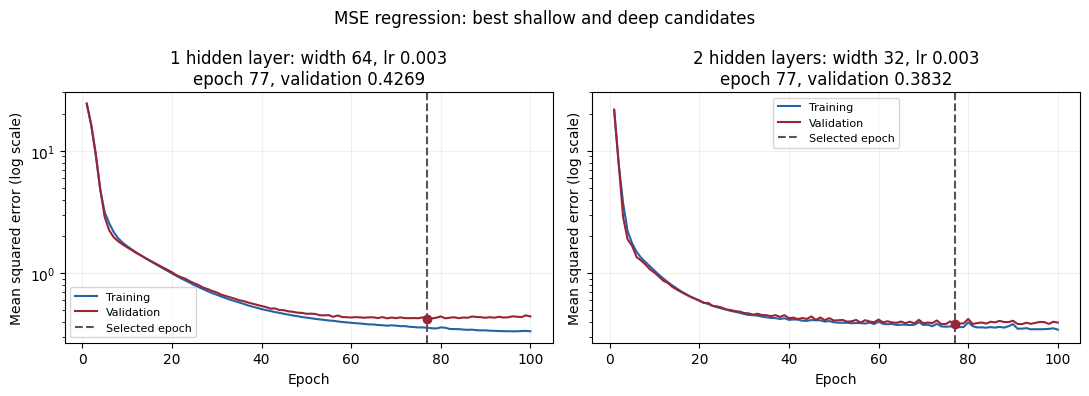

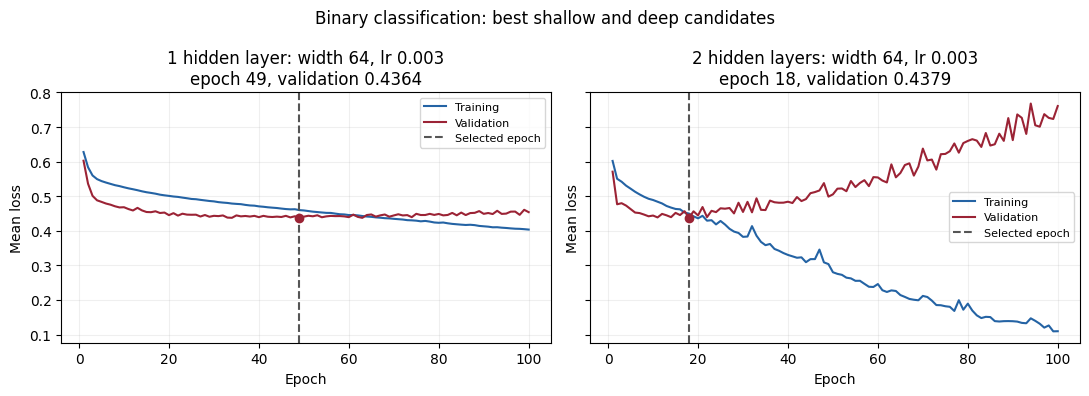

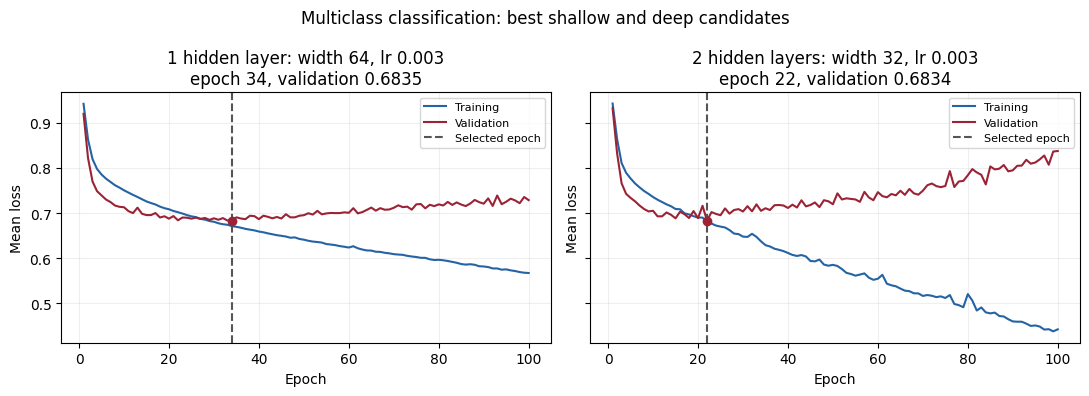

In [15]:
best_by_depth = {}
for task, spec in TASKS.items():
    best_by_depth[task] = {
        depth: min(
            (run for run in runs_by_task[task] if run["config"]["depth"] == depth),
            key=ranking_key,
        )
        for depth in PARAM_GRID["depth"]
    }
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for axis, depth in zip(axes, PARAM_GRID["depth"]):
        run = best_by_depth[task][depth]
        history = pd.DataFrame(run["history"])
        axis.plot(history["epoch"], history["training_loss"], label="Training", color="#2463a4")
        axis.plot(history["epoch"], history["validation_loss"], label="Validation", color="#9b2335")
        axis.axvline(run["selected_epoch"], color="#555555", linestyle="--", label="Selected epoch")
        axis.scatter(run["selected_epoch"], run["validation_loss"], color="#9b2335", zorder=3)
        config = run["config"]
        axis.set_title(
            f"{depth} hidden layer{'s' if depth > 1 else ''}: width {config['width']}, "
            f"lr {config['learning_rate']}\n"
            f"epoch {run['selected_epoch']}, validation {run['validation_loss']:.4f}"
        )
        axis.set_xlabel("Epoch")
        axis.set_ylabel("Mean loss")
        if task == "regression":
            axis.set_yscale("log")
            axis.set_ylabel("Mean squared error (log scale)")
        axis.grid(alpha=0.2)
        axis.legend(fontsize=8)
    fig.suptitle(spec["label"] + ": best shallow and deep candidates")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{task}_learning_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

## Did depth help?

The following comparisons use the measured validation losses. Each depth
receives its best width and learning rate from the grid, so this compares
the best candidate at each depth rather than isolating depth while
holding the other settings fixed.

In [16]:
for task, spec in TASKS.items():
    shallow, deep = best_by_depth[task][1], best_by_depth[task][2]
    relative_change = 100 * (shallow["validation_loss"] - deep["validation_loss"]) / shallow["validation_loss"]
    if relative_change > 0:
        conclusion = f"Two hidden layers helped in this search, lowering validation loss by {relative_change:.2f}%."
    elif relative_change < 0:
        conclusion = f"Two hidden layers did not help in this search: validation loss was {-relative_change:.2f}% higher."
    else:
        conclusion = "The two depths tied on validation loss; the parameter-count tie-break decides the selection."

    chosen = best_runs[task]
    gap = chosen["validation_loss"] - chosen["training_loss"]
    final_validation = chosen["history"][-1]["validation_loss"]
    epoch_comment = (
        f"Validation loss later reached {final_validation:.6f} at epoch 100, "
        "so retaining the earlier best weights avoids the later deterioration."
        if chosen["selected_epoch"] < EPOCHS and final_validation > chosen["validation_loss"]
        else "The selected epoch is also the final epoch; this run does not establish whether a longer budget would help."
    )
    display(Markdown(
        f"**{spec['label']}.** Best shallow validation loss: "
        f"**{shallow['validation_loss']:.6f}**; best deep validation loss: "
        f"**{deep['validation_loss']:.6f}**. {conclusion} "
        f"The selected model uses {chosen['config']['depth']} hidden layer(s), "
        f"width {chosen['config']['width']}, and learning rate "
        f"{chosen['config']['learning_rate']}. At epoch "
        f"{chosen['selected_epoch']}, its training loss is "
        f"{chosen['training_loss']:.6f} and validation loss is "
        f"{chosen['validation_loss']:.6f} (validation minus training: {gap:.6f}). "
        f"{epoch_comment}"
    ))
display(Markdown(
    "These conclusions describe one fixed split and one seed per candidate. "
    "They do not show that one depth is universally better. The classification "
    "curves can expose overfitting when training loss continues falling while "
    "validation loss rises. All 24 runs produced finite losses; the original "
    "grid and 100-epoch budget were retained without revision. No test-set "
    "results were used."
))

**MSE regression.** Best shallow validation loss: **0.426866**; best deep validation loss: **0.383229**. Two hidden layers helped in this search, lowering validation loss by 10.22%. The selected model uses 2 hidden layer(s), width 32, and learning rate 0.003. At epoch 77, its training loss is 0.367017 and validation loss is 0.383229 (validation minus training: 0.016212). Validation loss later reached 0.395894 at epoch 100, so retaining the earlier best weights avoids the later deterioration.

**Binary classification.** Best shallow validation loss: **0.436369**; best deep validation loss: **0.437874**. Two hidden layers did not help in this search: validation loss was 0.34% higher. The selected model uses 1 hidden layer(s), width 64, and learning rate 0.003. At epoch 49, its training loss is 0.459903 and validation loss is 0.436369 (validation minus training: -0.023534). Validation loss later reached 0.453972 at epoch 100, so retaining the earlier best weights avoids the later deterioration.

**Multiclass classification.** Best shallow validation loss: **0.683535**; best deep validation loss: **0.683368**. Two hidden layers helped in this search, lowering validation loss by 0.02%. The selected model uses 2 hidden layer(s), width 32, and learning rate 0.003. At epoch 22, its training loss is 0.680825 and validation loss is 0.683368 (validation minus training: 0.002543). Validation loss later reached 0.837529 at epoch 100, so retaining the earlier best weights avoids the later deterioration.

These conclusions describe one fixed split and one seed per candidate. They do not show that one depth is universally better. The classification curves can expose overfitting when training loss continues falling while validation loss rises. All 24 runs produced finite losses; the original grid and 100-epoch budget were retained without revision. No test-set results were used.

The regression improvement is appreciably larger than the differences between the classification candidates. In multiclass classification, the best depths differ by only about **0.00017** validation loss (roughly **0.02%**). Although the deeper model ranks first under the specified rule, this single split and seed provide little evidence of a reliable depth advantage.

The deeper binary and multiclass curves show training loss continuing to fall while validation loss rises later in training, which is consistent with overfitting. Keeping the earlier minimum-validation checkpoint matters more than using the final epoch. Some candidates with learning rate 0.001 select epoch 100, so those runs may still benefit from more training; the comparisons here are conditional on the required, equal 100-epoch budget. The grid and budget were not revised.

## Verify model selection and saved checkpoints

Check that all 24 candidates completed 100 epochs, reported losses come
from their minimum-validation epoch, and parameter counts match the
architecture. Reload the saved models and compare their losses with
a single full-set calculation to independently check batch weighting.
Verification uses only training and validation data.

In [17]:
assert sum(len(runs) for runs in runs_by_task.values()) == 24
for task, spec in TASKS.items():
    assert len(results_tables[task]) == 8
    for run in runs_by_task[task]:
        assert len(run["history"]) == EPOCHS
        assert [entry["epoch"] for entry in run["history"]] == list(range(1, EPOCHS + 1))
        assert all(
            math.isfinite(entry["training_loss"]) and math.isfinite(entry["validation_loss"])
            for entry in run["history"]
        )
        expected_record = min(run["history"], key=lambda entry: entry["validation_loss"])
        assert run["selected_epoch"] == expected_record["epoch"]
        assert run["training_loss"] == expected_record["training_loss"]
        assert run["validation_loss"] == expected_record["validation_loss"]
        width, depth = run["config"]["width"], run["config"]["depth"]
        expected_parameters = (
            (11 + 1) * width
            + (depth - 1) * (width + 1) * width
            + (width + 1) * spec["output_dim"]
        )
        assert run["parameter_count"] == expected_parameters

    best = min(runs_by_task[task], key=ranking_key)
    assert best is best_runs[task]
    checkpoint = torch.load(RESULTS_DIR / f"best_{task}.pt", map_location=DEVICE, weights_only=True)
    restored = build_mlp(checkpoint["depth"], checkpoint["width"], checkpoint["output_dim"]).to(DEVICE)
    restored.load_state_dict(checkpoint["state_dict"])
    restored.eval()
    assert isinstance(restored[-1], nn.Linear)
    criterion = spec["loss_factory"](reduction="mean")
    for split, loss_name in (("train", "training_loss"), ("validation", "validation_loss")):
        with torch.no_grad():
            outputs = restored(data[split]["X"].to(DEVICE))
            assert outputs.shape == (len(data[split]["X"]), spec["output_dim"])
            full_set_loss = criterion(outputs, data[split][spec["target"]].to(DEVICE)).item()
            selected_outputs = selected_models[task](data[split]["X"].to(DEVICE))
            torch.testing.assert_close(outputs, selected_outputs)
        np.testing.assert_allclose(full_set_loss, best[loss_name], atol=1e-6, rtol=1e-5)
    assert checkpoint["selected_epoch"] == best["selected_epoch"]

assert best_mse_model is selected_models["regression"]
print("All Part 3 checks passed: 24 runs, 100 epochs each, correct minimum-loss selection.")
print("Saved checkpoints reproduce their selected training and validation losses.")
print("Ready for later parts: selected_models, best_runs, best_mse_model, and best_mse_config.")

All Part 3 checks passed: 24 runs, 100 epochs each, correct minimum-loss selection.
Saved checkpoints reproduce their selected training and validation losses.
Ready for later parts: selected_models, best_runs, best_mse_model, and best_mse_config.


# Part 4 - Regression and predicted uncertainty

Part 4A reuses the MSE regression grid from Part 3. Part 4B trains one extra
model that predicts a mean and a variance. Predictions are kept as real
numbers so they are not rounded to a score or clipped to the score range.

Test-set results appear only in cells marked **final test evaluation**,
after all model and epoch selection is finished.

In [18]:
# Shared helpers

from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score,
)

def predict(model, X):
    """Run a model over a whole split and return its raw outputs.

    model.eval() and torch.no_grad() are applied here so no evaluation cell
    can forget them. Outputs are the network's unrestricted values
    (means, raw variances, or logits); any transformation happens later.
    """
    model.eval()
    with torch.no_grad():
        return model(X.to(DEVICE)).cpu()


def model_from_run(run, output_dim):
    """Rebuild a grid candidate and load the weights from its best validation epoch."""
    model = build_mlp(run["config"]["depth"], run["config"]["width"], output_dim).to(DEVICE)
    model.load_state_dict(run["state_dict"])
    model.eval()
    return model


def expected_parameter_count(depth, width, output_dim):
    """Closed-form count: (11 + 1) * width, plus (width + 1) * width per extra hidden layer,
    plus (width + 1) * output_dim for the output layer (the +1 terms are biases)."""
    return (11 + 1) * width + (depth - 1) * (width + 1) * width + (width + 1) * output_dim


def parameter_table(model):
    """Count weights and biases for each Linear layer, then check the total against PyTorch.

    A Linear layer with `in` inputs and `out` outputs has an (out x in) weight
    matrix, so in * out weights, plus one bias per output neuron. ReLU and
    Softplus have no trainable parameters.
    """
    rows = []
    linear_layers = [layer for layer in model if isinstance(layer, nn.Linear)]
    for number, layer in enumerate(linear_layers, start=1):
        weights = layer.in_features * layer.out_features
        biases = layer.out_features
        rows.append({
            "layer": f"Linear {number}",
            "in -> out": f"{layer.in_features} -> {layer.out_features}",
            "weights (in x out)": weights,
            "biases (out)": biases,
            "total": weights + biases,
        })
    table = pd.DataFrame(rows).set_index("layer")
    # The hand calculation must agree with PyTorch's own trainable-parameter count.
    assert table["total"].sum() == count_parameters(model)
    table.loc["Total"] = ["", table["weights (in x out)"].sum(), table["biases (out)"].sum(),
                          table["total"].sum()]
    return table


def draw_mlp(depth, width, output_dim, title, output_note=""):
    """Draw the architecture as boxes: 11 inputs -> hidden Linear+ReLU blocks -> output Linear.

    The output layer has no activation, so it stays unrestricted; `output_note`
    describes how its values are interpreted (e.g. a logit, or mean + variance).
    """
    labels = ["Input\n11 scaled\nfeatures"]
    for layer in range(1, depth + 1):
        fan_in = 11 if layer == 1 else width   # first hidden layer reads the 11 features
        labels.append(f"Hidden {layer}\nLinear({fan_in}→{width})\n+ ReLU")
    labels.append(f"Output\nLinear({width}→{output_dim})" + (f"\n{output_note}" if output_note else ""))

    step = 2.6   # horizontal distance between box left edges
    fig, ax = plt.subplots(figsize=(step * len(labels), 2.4))
    for i, label in enumerate(labels):
        # Input and output boxes are blue; hidden layers are red-tinted.
        colour = "#e8eef6" if i in (0, len(labels) - 1) else "#f3e5e8"
        ax.add_patch(FancyBboxPatch((i * step, 0), 2.0, 1.4, boxstyle="round,pad=0.05",
                                    facecolor=colour, edgecolor="#333333"))
        ax.text(i * step + 1.0, 0.7, label, ha="center", va="center", fontsize=9)
        if i:   # arrow from the previous box to this one
            ax.annotate("", xy=(i * step - 0.07, 0.7), xytext=(i * step - 0.53, 0.7),
                        arrowprops=dict(arrowstyle="->"))
    ax.set_xlim(-0.2, step * len(labels))
    ax.set_ylim(-0.3, 1.8)
    ax.axis("off")
    ax.set_title(title)
    plt.show()

## 4A. Predict the quality score using MSE

### 4A1. Selected MSE model: architecture and parameter count

The regression grid is the eight-candidate MSE grid already run in Part 3,
ranked by validation MSE. The selected model's weights come from its
lowest-validation-loss epoch.

**MSE regression grid (from Part 3), ranked by validation MSE**

,candidate,depth,width,learning_rate,parameter_count,selected_epoch,training_loss,validation_loss
rank,,,,,,,,
1,7,2,32,0.003,1473,77,0.367017,0.383229
2,8,2,64,0.003,4993,30,0.382132,0.388367
3,6,2,64,0.001,4993,66,0.364794,0.394579
4,4,1,64,0.003,833,77,0.359079,0.426866
5,3,1,32,0.003,417,98,0.399813,0.457242
6,5,2,32,0.001,1473,98,0.405161,0.459054
7,2,1,64,0.001,833,100,0.548981,0.597023
8,1,1,32,0.001,417,100,0.631744,0.628483


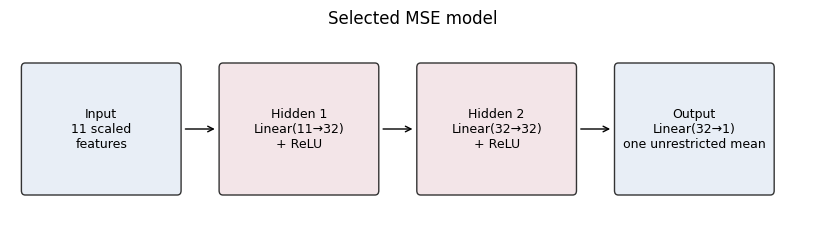

,in -> out,weights (in x out),biases (out),total
layer,,,,
Linear 1,11 -> 32,352,32,384
Linear 2,32 -> 32,1024,32,1056
Linear 3,32 -> 1,32,1,33
Total,,1408,65,1473


Hand-calculated total = 1473, PyTorch count = 1473
Selected MSE model is also the best deep MSE model: True


In [19]:
# Part 3 already ran the 8-candidate MSE grid; Part 4A uses those exact runs.
regression_run = best_runs["regression"]                                  # rank 1 by validation MSE
deep_mse_run = best_by_depth["regression"][max(PARAM_GRID["depth"])]     # best 2-layer candidate
mse_model = selected_models["regression"]                                 # weights from its best epoch

# If the selected model is already the best deep model, reuse it instead of rebuilding.
deep_mse_model = mse_model if deep_mse_run is regression_run else model_from_run(deep_mse_run, 1)

display(Markdown("**MSE regression grid (from Part 3), ranked by validation MSE**"))
display(results_tables["regression"].round(6))

mse_config = regression_run["config"]
draw_mlp(mse_config["depth"], mse_config["width"], 1, "Selected MSE model", "one unrestricted mean")

mse_parameters = parameter_table(mse_model)
display(mse_parameters)
print(f"Hand-calculated total = {mse_parameters.loc['Total', 'total']}, "
      f"PyTorch count = {count_parameters(mse_model)}")
print("Selected MSE model is also the best deep MSE model:", deep_mse_run is regression_run)

**Parameter calculation for the selected model (11 → 32 → 32 → 1).**
A Linear layer with $n_\text{in}$ inputs and $n_\text{out}$ outputs has
$n_\text{in}\times n_\text{out}$ weights and $n_\text{out}$ biases.

| Layer | Weights | Biases | Total |
| --- | ---: | ---: | ---: |
| Linear 1 (11 → 32) | 11 × 32 = 352 | 32 | 384 |
| Linear 2 (32 → 32) | 32 × 32 = 1024 | 32 | 1056 |
| Output (32 → 1) | 32 × 1 = 32 | 1 | 33 |
| **Total** | 1408 | 65 | **1473** |

ReLU layers add no parameters. The code above checks this total against
PyTorch's count of trainable parameters.

### 4A2. Constant baseline versus the MLP on validation data

* **RMSE** $=\sqrt{\frac1N\sum_i (y_i-\hat y_i)^2}$, the square root of MSE.
  Squaring weights large misses heavily; the square root returns the value to
  **quality-score points**.
* **MAE** $=\frac1N\sum_i |y_i-\hat y_i|$, the average absolute miss, also in
  **quality-score points**. It is less sensitive to a few large errors.

The baseline always predicts the **training-set** mean quality. It ignores the
inputs, so any improvement over it shows the MLP learned something from the
11 measurements.

In [20]:
def regression_metrics(predicted, actual):
    """MSE, RMSE and MAE for real-valued predictions (no rounding or clipping)."""
    error = predicted - actual
    mse = error.square().mean().item()
    return {"MSE": mse, "RMSE": math.sqrt(mse), "MAE": error.abs().mean().item()}


# Baseline: always predict the mean quality of the TRAINING set (never validation/test).
train_mean_quality = data["train"]["y_regression"].mean().item()


def baseline_prediction(split):
    """The constant baseline as an (N, 1) tensor for the given split."""
    return torch.full_like(data[split]["y_regression"], train_mean_quality)


y_validation = data["validation"]["y_regression"]
mse_validation_pred = predict(mse_model, data["validation"]["X"])
assert mse_validation_pred.shape == y_validation.shape            # both (N, 1)

# Sanity check: recomputed validation MSE must equal the loss recorded during selection.
np.testing.assert_allclose(
    regression_metrics(mse_validation_pred, y_validation)["MSE"],
    regression_run["validation_loss"], rtol=1e-5,
)

validation_regression = pd.DataFrame({
    "Training-mean baseline": regression_metrics(baseline_prediction("validation"), y_validation),
    "Selected MSE MLP": regression_metrics(mse_validation_pred, y_validation),
}).T[["RMSE", "MAE"]]
print(f"Training-set mean quality (constant baseline): {train_mean_quality:.4f}")
display(validation_regression.round(4))

Training-set mean quality (constant baseline): 5.6172


,RMSE,MAE
Training-mean baseline,0.8130,0.6916
Selected MSE MLP,0.6191,0.4772


### 4A3. Final test evaluation: MSE model and baseline

All model, setting and epoch choices are complete. The test set is used here
for the first time and does not change any choice.

,MSE,RMSE,MAE
Training-mean baseline,0.6795,0.8243,0.6916
Selected MSE MLP,0.4416,0.6645,0.4967


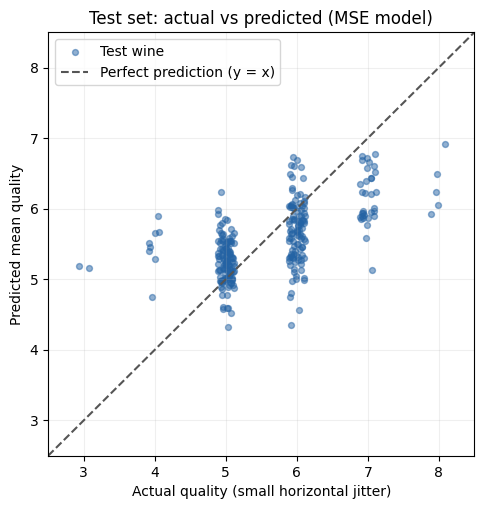

In [21]:
# FINAL TEST EVALUATION — all selection is finished; nothing below changes a choice.
y_test = data["test"]["y_regression"]
mse_test_pred = predict(mse_model, data["test"]["X"])

test_regression = pd.DataFrame({
    "Training-mean baseline": regression_metrics(baseline_prediction("test"), y_test),
    "Selected MSE MLP": regression_metrics(mse_test_pred, y_test),
}).T
display(test_regression.round(4))

actual = y_test.squeeze(1).numpy()
predicted = mse_test_pred.squeeze(1).numpy()

# Scores are whole numbers, so points would stack in vertical lines.
# A small, seeded horizontal jitter separates them for display only.
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.12, 0.12, len(actual))
limits = [min(actual.min(), predicted.min()) - 0.5, max(actual.max(), predicted.max()) + 0.5]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(actual + jitter, predicted, alpha=0.5, s=18, color="#2463a4", label="Test wine")
ax.plot(limits, limits, "--", color="#555555", label="Perfect prediction (y = x)")
ax.set(xlim=limits, ylim=limits, xlabel="Actual quality (small horizontal jitter)",
       ylabel="Predicted mean quality", title="Test set: actual vs predicted (MSE model)")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 4B. Predict a mean and a variance using Gaussian NLL

One extra model (not a grid) uses the depth, width and learning rate of the
best **deep** MSE candidate, but has **two** outputs per example: a mean and a
raw variance value. The final Linear layer stays unrestricted. Softplus is
applied afterwards to make the variance positive, and 0.0001 is added so it
can never reach zero.

The loss below takes `(outputs, target)` exactly like `nn.MSELoss`, so the
Part 3 `train_candidate` and `mean_loss` functions train and evaluate this
model without any changes: same seed, Adam, batch size 64, 100 epochs, and
checkpoint selection by validation Gaussian NLL.

In [22]:
class GaussianNLLCriterion(nn.Module):
    """Gaussian NLL for a network with two raw outputs per example.

    Column 0 is the mean (left unrestricted). Column 1 is a raw value that
    Softplus maps to a positive number; 0.0001 is added so the variance can
    never reach zero (which would make the loss blow up).
    """

    def __init__(self):
        super().__init__()
        self.softplus = nn.Softplus()
        self.nll = nn.GaussianNLLLoss(full=True, reduction="mean")   # full=True keeps the log(2π) constant

    def split(self, raw_outputs):
        """Return the mean and positive variance as two separate (N, 1) tensors."""
        mean = raw_outputs[:, 0:1]                               # slicing 0:1 keeps shape (N, 1)
        variance = self.softplus(raw_outputs[:, 1:2]) + 1e-4     # always > 0
        return mean, variance

    def forward(self, raw_outputs, target):
        mean, variance = self.split(raw_outputs)
        return self.nll(mean, target, variance)


# Copy the hyperparameters of the best DEEP MSE candidate (depth, width, learning rate).
gaussian_config = dict(deep_mse_run["config"])
gaussian_criterion = GaussianNLLCriterion()

# Same training function as Part 3: seed 4110, fresh Adam, batch size 64, 100 epochs,
# and the checkpoint is chosen by the lowest VALIDATION Gaussian NLL.
gaussian_run = train_candidate(
    config=gaussian_config,
    output_dim=2,                       # one mean + one raw variance per example
    criterion=gaussian_criterion,
    train_data=TensorDataset(data["train"]["X"], data["train"]["y_regression"]),
    validation_data=TensorDataset(data["validation"]["X"], data["validation"]["y_regression"]),
)
gaussian_model = model_from_run(gaussian_run, 2)
print(f"Gaussian NLL model {gaussian_config}: selected epoch {gaussian_run['selected_epoch']}, "
      f"training NLL {gaussian_run['training_loss']:.6f}, "
      f"validation NLL {gaussian_run['validation_loss']:.6f}")

Gaussian NLL model {'depth': 2, 'learning_rate': 0.003, 'width': 32}: selected epoch 84, training NLL 0.824436, validation NLL 0.928108


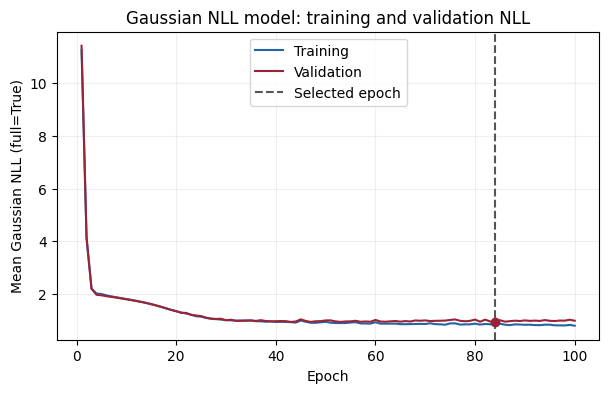

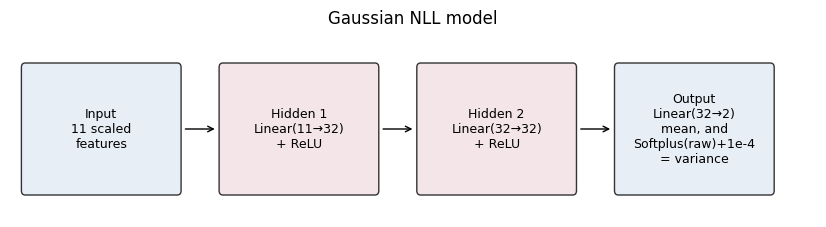

,in -> out,weights (in x out),biases (out),total
layer,,,,
Linear 1,11 -> 32,352,32,384
Linear 2,32 -> 32,1024,32,1056
Linear 3,32 -> 2,64,2,66
Total,,1440,66,1506


Hand-calculated total = 1506, PyTorch count = 1506


In [23]:
# Training and validation NLL per epoch, measured on the full sets in eval mode (from train_candidate).
gaussian_history = pd.DataFrame(gaussian_run["history"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(gaussian_history["epoch"], gaussian_history["training_loss"], label="Training", color="#2463a4")
ax.plot(gaussian_history["epoch"], gaussian_history["validation_loss"], label="Validation", color="#9b2335")
ax.axvline(gaussian_run["selected_epoch"], color="#555555", linestyle="--", label="Selected epoch")
ax.scatter(gaussian_run["selected_epoch"], gaussian_run["validation_loss"], color="#9b2335", zorder=3)
ax.set(xlabel="Epoch", ylabel="Mean Gaussian NLL (full=True)",
       title="Gaussian NLL model: training and validation NLL")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

draw_mlp(gaussian_config["depth"], gaussian_config["width"], 2, "Gaussian NLL model",
         "mean, and\nSoftplus(raw)+1e-4\n= variance")

# Softplus adds no parameters; only the output layer differs from the MSE model (2 outputs, not 1).
gaussian_parameters = parameter_table(gaussian_model)
display(gaussian_parameters)
print(f"Hand-calculated total = {gaussian_parameters.loc['Total', 'total']}, "
      f"PyTorch count = {count_parameters(gaussian_model)}")

**Parameter calculation (11 → 32 → 32 → 2).** The hidden layers match the
MSE model: 384 + 1056 = 1440. The output layer now has
32 × 2 = 64 weights and 2 biases, so 66 parameters. The total is
**1506**, 33 more than the MSE model. Softplus has no parameters.

### Validation RMSE and MAE versus the deep MSE model

Only the point predictions are compared here: the Gaussian model's predicted
mean against the deep MSE model's prediction, both on validation data.

In [24]:
X_validation = data["validation"]["X"]
gaussian_validation_mean, gaussian_validation_var = gaussian_criterion.split(
    predict(gaussian_model, X_validation)
)
# Required shapes and a strictly positive variance.
assert gaussian_validation_mean.shape == gaussian_validation_var.shape == y_validation.shape
assert (gaussian_validation_var > 0).all()

# Compare point predictions only: the Gaussian model's mean vs the deep MSE model's mean.
validation_comparison = pd.DataFrame({
    "Deep MSE model": regression_metrics(predict(deep_mse_model, X_validation), y_validation),
    "Gaussian NLL model (mean)": regression_metrics(gaussian_validation_mean, y_validation),
}).T[["RMSE", "MAE"]]
display(validation_comparison.round(4))

validation_sd = gaussian_validation_var.sqrt()
print(f"Predicted validation SD: min {validation_sd.min().item():.3f}, "
      f"median {validation_sd.median().item():.3f}, max {validation_sd.max().item():.3f}")

,RMSE,MAE
Deep MSE model,0.6191,0.4772
Gaussian NLL model (mean),0.6366,0.4819


Predicted validation SD: min 0.230, median 0.594, max 0.898


**Why learning the variance changes the objective.** For one example the full
Gaussian NLL is

$$
\ell=\tfrac12\log(2\pi\sigma^2)+\frac{(y-\mu)^2}{2\sigma^2}.
$$

* With a **fixed** variance this is just a scaled and shifted MSE, so it ranks
  means exactly as MSE does. When the network **learns** $\sigma^2$, each
  squared error is divided by that example's own variance. Examples the model
  marks as uncertain pull less on the mean, so the fit is no longer plain
  least squares and RMSE/MAE can change.
* The **$\tfrac12\log\sigma^2$ term** grows as the variance grows. Inflating
  $\sigma^2$ shrinks the error term but raises this term, so predicting a huge
  variance is not a free way to lower the loss. For a given squared error, the
  loss is smallest when $\sigma^2$ equals that squared error, so the variance
  is pushed toward the size of the errors the model actually makes.

### Final test evaluation: comparison table

The selected MSE model and the best deep MSE model are compared with the
Gaussian model on the test set. When they are the same model, the table uses
one row. Test Gaussian NLL is reported separately, since an NLL value cannot
be compared with an MSE value.

In [25]:
# FINAL TEST EVALUATION for the uncertainty experiment.
raw_test = predict(gaussian_model, data["test"]["X"])
gaussian_test_mean, gaussian_test_var = gaussian_criterion.split(raw_test)
gaussian_test_nll = gaussian_criterion(raw_test, y_test).item()


def architecture(cfg):
    return f"{cfg['depth']} x {cfg['width']} ReLU, lr {cfg['learning_rate']}"


# One row when the selected MSE model is also the best deep MSE model; otherwise two rows.
mse_rows = (
    [("Selected MSE (= best deep MSE)", regression_run, mse_model)]
    if deep_mse_run is regression_run
    else [("Selected MSE", regression_run, mse_model), ("Best deep MSE", deep_mse_run, deep_mse_model)]
)
comparison_rows = []
for name, run, model in mse_rows:
    metrics = regression_metrics(predict(model, data["test"]["X"]), y_test)
    comparison_rows.append({"model": name, "hidden architecture": architecture(run["config"]),
                            "parameters": count_parameters(model),
                            "test RMSE": metrics["RMSE"], "test MAE": metrics["MAE"]})

metrics = regression_metrics(gaussian_test_mean, y_test)   # point predictions = the predicted means
comparison_rows.append({"model": "Gaussian NLL (mean)", "hidden architecture": architecture(gaussian_config),
                        "parameters": count_parameters(gaussian_model),
                        "test RMSE": metrics["RMSE"], "test MAE": metrics["MAE"]})
display(pd.DataFrame(comparison_rows).set_index("model").round(4))

# Reported on its own line: an NLL value is not comparable with an MSE value.
print(f"Gaussian NLL model test NLL (reported separately): {gaussian_test_nll:.4f}")

# How often the actual score lands inside mean ± 2 SD (used in the interpretation below).
test_sd = gaussian_test_var.sqrt()
coverage = ((y_test - gaussian_test_mean).abs() <= 2 * test_sd).float().mean().item()
print(f"Share of test scores inside mean ± 2 predicted SD: {coverage:.1%}")
print(f"Predicted test SD: min {test_sd.min().item():.3f}, "
      f"median {test_sd.median().item():.3f}, max {test_sd.max().item():.3f}")

,hidden architecture,parameters,test RMSE,test MAE
model,,,,
Selected MSE (= best deep MSE),"2 x 32 ReLU, lr 0.003",1473,0.6645,0.4967
Gaussian NLL (mean),"2 x 32 ReLU, lr 0.003",1506,0.6406,0.4914


Gaussian NLL model test NLL (reported separately): 0.9305
Share of test scores inside mean ± 2 predicted SD: 93.4%
Predicted test SD: min 0.240, median 0.600, max 1.024


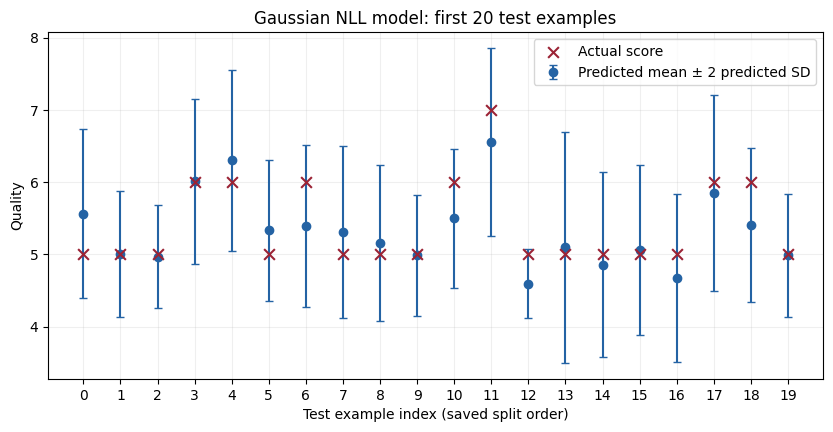

In [26]:
n_show = 20
index = np.arange(n_show)                                       # position in the saved test order
mean_20 = gaussian_test_mean[:n_show].squeeze(1).numpy()
std_20 = gaussian_test_var[:n_show].sqrt().squeeze(1).numpy()   # standard deviation = sqrt(variance)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(index, mean_20, yerr=2 * std_20, fmt="o", capsize=3, color="#2463a4",
            label="Predicted mean ± 2 predicted SD")
ax.scatter(index, y_test[:n_show].squeeze(1).numpy(), marker="x", s=60, color="#9b2335",
           zorder=3, label="Actual score")
ax.set(xticks=index, xlabel="Test example index (saved split order)", ylabel="Quality",
       title="Gaussian NLL model: first 20 test examples")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### Interpretation

The Gaussian model's predicted means are close to the MSE model's: validation
RMSE 0.637 vs 0.619 and MAE 0.482 vs 0.477, and test RMSE 0.641 vs 0.665 and
MAE 0.491 vs 0.497, so learning a variance neither clearly helped nor hurt the
point predictions. Both models pull predictions toward the middle of the
scale (the scatter plot has almost no predictions below 4.3 or above 7), so
wines rated 3, 4 or 8 are the worst predicted. The MSE model is
**homoscedastic**: it implicitly assumes one shared, fixed noise variance for
every wine, while the Gaussian model is **heteroscedastic** and predicts a
separate variance for each wine; its predicted test standard deviations range
from 0.24 to 1.02 (median 0.60), so some intervals are narrow (example 12)
and others wide (example 13). On the test set, 93.4% of actual scores fall
inside mean ± 2 predicted SD, close to but not exactly the nominal 95%. That
coverage is not guaranteed, because "±2σ ≈ 95%" holds only if each score
really follows a Gaussian with exactly the predicted mean and variance, while
these scores are discrete integers, the variances are learned from only 815
training wines, and the checkpoint was chosen by validation NLL rather than
calibrated for coverage. The test NLL of 0.93 is not compared with any MSE
value, since the two losses measure different things on different scales.

# Part 5 - Binary classification using BCE

The model outputs one unrestricted **logit** per wine and was trained with
`nn.BCEWithLogitsLoss` in the Part 3 grid, with predictions and targets both
of shape `(N, 1)`. The model contains no sigmoid. Sigmoid is applied **only
for evaluation**, to turn logits into class-1 probabilities, and a fixed
threshold of 0.5 turns probabilities into class predictions.

## 5.1. Selected model: architecture and parameter count

**Binary grid (from Part 3), ranked by validation BCE**

,candidate,depth,width,learning_rate,parameter_count,selected_epoch,training_loss,validation_loss
rank,,,,,,,,
1,4,1,64,0.003,833,49,0.459903,0.436369
2,8,2,64,0.003,4993,18,0.449821,0.437874
3,3,1,32,0.003,417,34,0.486248,0.440072
4,2,1,64,0.001,833,95,0.480539,0.440750
5,6,2,64,0.001,4993,34,0.463523,0.441038
6,7,2,32,0.003,1473,22,0.468890,0.442862
7,1,1,32,0.001,417,95,0.489783,0.444196
8,5,2,32,0.001,1473,34,0.498264,0.448814


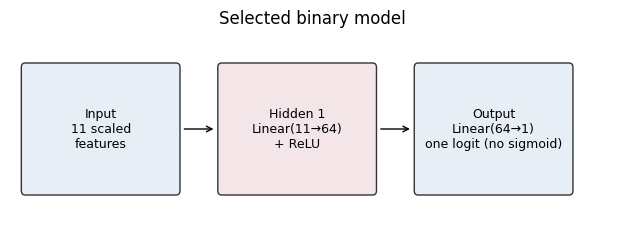

,in -> out,weights (in x out),biases (out),total
layer,,,,
Linear 1,11 -> 64,704,64,768
Linear 2,64 -> 1,64,1,65
Total,,768,65,833


Hand-calculated total = 833, PyTorch count = 833
Selected epoch 49, validation BCE 0.436369


In [27]:
binary_run = best_runs["binary"]           # rank 1 by validation BCE in Part 3
binary_model = selected_models["binary"]   # weights from its best validation epoch

# The last layer must be Linear: no sigmoid inside the model before BCEWithLogitsLoss.
assert isinstance(binary_model[-1], nn.Linear)

display(Markdown("**Binary grid (from Part 3), ranked by validation BCE**"))
display(results_tables["binary"].round(6))

binary_config = binary_run["config"]
draw_mlp(binary_config["depth"], binary_config["width"], 1, "Selected binary model",
         "one logit (no sigmoid)")

binary_parameters = parameter_table(binary_model)
display(binary_parameters)
print(f"Hand-calculated total = {binary_parameters.loc['Total', 'total']}, "
      f"PyTorch count = {count_parameters(binary_model)}")
print(f"Selected epoch {binary_run['selected_epoch']}, validation BCE {binary_run['validation_loss']:.6f}")

**Parameter calculation (11 → 64 → 1).** The hidden layer has
11 × 64 = 704 weights and 64 biases (768). The output layer has
64 × 1 = 64 weights and 1 bias (65). The total is **833**.

## 5.2–5.4. Final test evaluation: baseline, metrics and confusion matrix

* Probability of class 1: $p=\sigma(z)=1/(1+e^{-z})$ for logit $z$.
* Predicted class: 1 if $p \ge 0.5$, otherwise 0. The threshold is fixed and
  never tuned.
* The baseline always predicts the most frequent **training** label.
* **Precision (class 1)**: of the wines predicted as quality ≥ 6, the share
  that really are. It measures how trustworthy a positive prediction is.
* **Recall (class 1)**: of the wines that really are quality ≥ 6, the share
  the model finds. It measures how many positives are missed.
* **F1 (class 1)**: the harmonic mean of precision and recall. It is high only
  when both are high.

Most frequent training label: 1


,accuracy,precision (class 1),recall (class 1),F1 (class 1)
Constant baseline (always 1),0.5294,0.5294,1.0000,0.6923
Selected BCE MLP,0.8015,0.8358,0.7778,0.8058


MLP test BCE: 0.4658


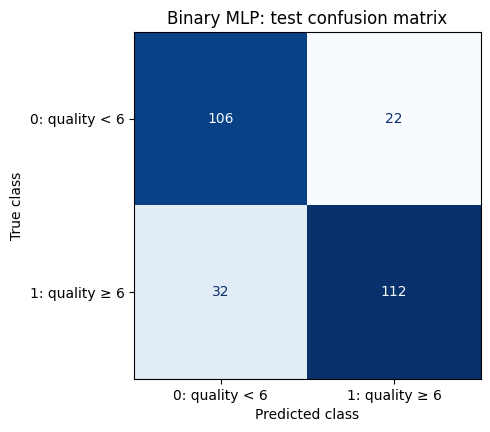

In [28]:
# FINAL TEST EVALUATION — the model and epoch were chosen on validation BCE only.
THRESHOLD = 0.5                                       # fixed; never tuned
y_test_binary = data["test"]["y_binary"]              # float32, shape (N, 1)
test_logits = predict(binary_model, data["test"]["X"])
assert test_logits.shape == y_test_binary.shape == (len(test_idx), 1)

test_probability = torch.sigmoid(test_logits)                  # logit -> P(class 1)
test_predicted = (test_probability >= THRESHOLD).long()        # class 1 if P >= 0.5

# Test BCE is computed on the LOGITS, exactly like training.
test_bce = nn.BCEWithLogitsLoss(reduction="mean")(test_logits, y_test_binary).item()

# scikit-learn wants flat integer label arrays.
y_true = y_test_binary.squeeze(1).long().numpy()
y_pred = test_predicted.squeeze(1).numpy()

# Baseline: always predict the most frequent label in the TRAINING split.
majority_label = int(targets["binary"].iloc[train_idx].value_counts().idxmax())
y_baseline = np.full_like(y_true, majority_label)


def binary_scores(predictions):
    """Accuracy plus precision/recall/F1 for class 1 (zero_division=0 avoids warnings)."""
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision (class 1)": precision_score(y_true, predictions, zero_division=0),
        "recall (class 1)": recall_score(y_true, predictions, zero_division=0),
        "F1 (class 1)": f1_score(y_true, predictions, zero_division=0),
    }


binary_results = pd.DataFrame({
    f"Constant baseline (always {majority_label})": binary_scores(y_baseline),
    "Selected BCE MLP": binary_scores(y_pred),
}).T
print(f"Most frequent training label: {majority_label}")
display(binary_results.round(4))
print(f"MLP test BCE: {test_bce:.4f}")

# Confusion matrix: rows = true class, columns = predicted class.
test_confusion = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(
    test_confusion, display_labels=["0: quality < 6", "1: quality ≥ 6"],
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(xlabel="Predicted class", ylabel="True class", title="Binary MLP: test confusion matrix")
plt.show()

**Why accuracy alone may hide errors.** The constant baseline that always
predicts class 1 already reaches 52.9% accuracy and a perfect recall of 1.0,
yet it never identifies a single quality < 6 wine; its precision of 0.529 is
simply the share of class 1 in the test set. Accuracy merges both kinds of
mistake into one number. The confusion matrix separates them: the MLP makes
22 false positives (quality < 6 wines predicted as ≥ 6) and 32 false
negatives (good wines missed). Precision and recall show whether a model errs
by over- or under-predicting class 1, which matters when the two mistakes
have different costs.

## 5.5. First five test examples

Per-example BCE is $-\log$ of the probability the model gives to the **true**
label. If all five are correct, the first incorrect test prediction is added.

In [29]:
# Per-example BCE on logits: -log(probability the model gives to the TRUE label).
per_example_bce = nn.BCEWithLogitsLoss(reduction="none")(test_logits, y_test_binary).squeeze(1)
correct = test_predicted.squeeze(1) == y_test_binary.squeeze(1).long()

rows_to_show = list(range(5))            # first five in saved test order
if correct[:5].all():                    # all right? then also show the first mistake, if any
    incorrect = torch.nonzero(~correct).flatten()
    if len(incorrect):
        rows_to_show.append(int(incorrect[0]))

display(pd.DataFrame([{
    "test position": i,
    "true label": int(y_true[i]),
    "p(class 1)": test_probability[i].item(),
    "predicted class": int(y_pred[i]),
    "per-example BCE": per_example_bce[i].item(),
    "correct": bool(correct[i]),
} for i in rows_to_show]).set_index("test position").round(4))

,true label,p(class 1),predicted class,per-example BCE,correct
test position,,,,,
0,0,0.6047,1,0.9281,False
1,0,0.3018,0,0.3592,True
2,0,0.0739,0,0.0768,True
3,1,0.8457,1,0.1676,True
4,1,0.9077,1,0.0968,True


### How confidence affects the loss

Test example 0 (true label 0) is the only mistake among the first five. The
model gives it a class-1 probability of 0.605, so its BCE is
$-\log(1-0.605)=0.928$. Because that probability is close to 0.5, this unsure
mistake is penalised only moderately; a confident mistake at $p=0.95$ would
cost $-\log(0.05)\approx 3.0$. Correct predictions also differ: example 2
($p=0.074$, label 0) costs only 0.077, while example 1 is still correct but
less sure ($p=0.302$, label 0) and costs 0.359.

### Results

The selected MLP (one hidden layer of 64 units) reaches **80.1%** test
accuracy against **52.9%** for the majority-class baseline, with class-1
precision 0.836, recall 0.778, F1 0.806 and test BCE 0.466; it misses slightly
more good wines (32) than it wrongly accepts (22). BCE can fall without any
change in accuracy because accuracy only checks which side of 0.5 each
probability lies on: moving a correct prediction from $p=0.6$ to $p=0.9$
lowers its loss from 0.51 to 0.11 without changing the predicted class.
Applying the 0.5 threshold **before** calculating BCE would replace the
probabilities with hard 0/1 values. That step function has zero gradient
almost everywhere, so no learning signal would reach the weights, and each
loss would be either 0 or (clamped) infinite, losing all information about how
close or how confident the model was.

# Part 6 — Multiclass classification using cross entropy

The target is one of three mutually exclusive classes: 0 for quality ≤ 5, 1 for quality = 6, and 2 for quality ≥ 7. The selected model is the Part 3 multiclass candidate with the lowest validation cross entropy; this section reuses its best-epoch weights and does not train another model. The final test set is used only after model selection.

## 6.1. Selected model, architecture, and parameter count


**Multiclass grid from Part 3, ranked by validation cross entropy**

,candidate,depth,width,learning_rate,parameter_count,selected_epoch,training_loss,validation_loss
rank,,,,,,,,
1,7,2,32,0.003,1539,22,0.680825,0.683368
2,4,1,64,0.003,963,34,0.671242,0.683535
3,2,1,64,0.001,963,95,0.673097,0.685127
4,3,1,32,0.003,483,63,0.660179,0.686038
5,5,2,32,0.001,1539,45,0.700194,0.689392
6,8,2,64,0.003,5123,18,0.649179,0.691756
7,1,1,32,0.001,483,95,0.704389,0.694896
8,6,2,64,0.001,5123,34,0.664740,0.695389


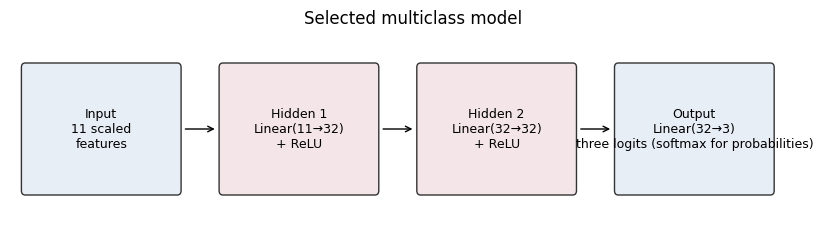

,in -> out,weights (in x out),biases (out),total
layer,,,,
Linear 1,11 -> 32,352,32,384
Linear 2,32 -> 32,1024,32,1056
Linear 3,32 -> 3,96,3,99
Total,,1472,67,1539


Selected epoch 22; validation cross entropy 0.683368; hand-calculated and PyTorch parameter count 1539


In [30]:
multiclass_run = best_runs["multiclass"]
multiclass_model = selected_models["multiclass"]
multiclass_config = multiclass_run["config"]

# CrossEntropyLoss receives raw logits; no softmax belongs inside the model.
assert isinstance(multiclass_model[-1], nn.Linear)
assert multiclass_model[-1].out_features == 3
assert data["train"]["y_multiclass"].dtype == torch.long
assert data["train"]["y_multiclass"].ndim == 1

display(Markdown("**Multiclass grid from Part 3, ranked by validation cross entropy**"))
display(results_tables["multiclass"].round(6))

draw_mlp(
    multiclass_config["depth"], multiclass_config["width"], 3,
    "Selected multiclass model", "three logits (softmax for probabilities)",
)
multiclass_parameters = parameter_table(multiclass_model)
display(multiclass_parameters)
print(
    f"Selected epoch {multiclass_run['selected_epoch']}; "
    f"validation cross entropy {multiclass_run['validation_loss']:.6f}; "
    f"hand-calculated and PyTorch parameter count "
    f"{multiclass_parameters.loc['Total', 'total']}"
)


## 6.2. Final test evaluation: loss, accuracy, macro F1, and baseline

Convert the selected model's logits to class indices with argmax. The baseline always predicts the most frequent class in the training split. Rows of the confusion matrix are true classes and columns are predicted classes.


Selected MLP test cross entropy: 0.7115
Most frequent training class: 0


,accuracy,macro F1
Selected cross-entropy MLP,0.6581,0.6007
Training-majority baseline (always 0),0.4706,0.2133


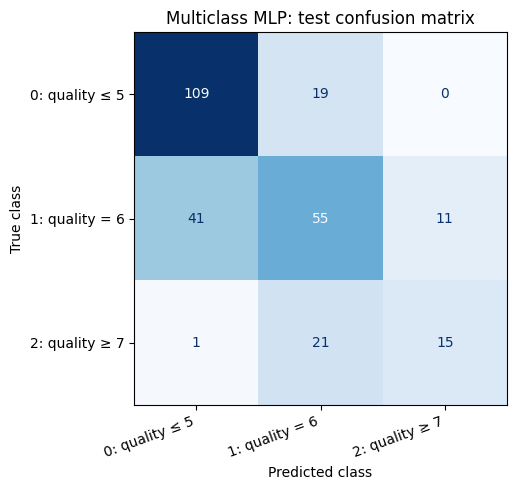

Most often confused pair: classes 0 (quality ≤ 5) and 1 (quality = 6), with 60 combined errors in both directions.
Interpretation: These are adjacent quality groups whose score ranges meet at a class boundary. Wines on either side of that cutoff can have similar measured features, which may contribute to confusion.
This is a plausible explanation for the observed errors, not proof that ordering alone caused them.


In [31]:
# FINAL TEST EVALUATION — selection used validation loss only.
multiclass_y_test = data["test"]["y_multiclass"]
multiclass_test_logits = predict(multiclass_model, data["test"]["X"])
assert multiclass_test_logits.shape == (len(test_idx), 3)
assert multiclass_y_test.shape == (len(test_idx),)
assert multiclass_y_test.dtype == torch.long

multiclass_test_ce = nn.CrossEntropyLoss(reduction="mean")(
    multiclass_test_logits, multiclass_y_test
).item()
multiclass_test_pred = multiclass_test_logits.argmax(dim=1)
multiclass_y_true_np = multiclass_y_test.numpy()
multiclass_y_pred_np = multiclass_test_pred.numpy()

multiclass_majority = int(
    targets["multiclass"].iloc[train_idx].value_counts().idxmax()
)
multiclass_baseline_pred = np.full_like(multiclass_y_true_np, multiclass_majority)
class_labels = [0, 1, 2]
class_names = ["0: quality ≤ 5", "1: quality = 6", "2: quality ≥ 7"]

print(f"Selected MLP test cross entropy: {multiclass_test_ce:.4f}")
multiclass_test_scores = pd.DataFrame({
    "accuracy": {
        "Selected cross-entropy MLP": accuracy_score(
            multiclass_y_true_np, multiclass_y_pred_np
        ),
        f"Training-majority baseline (always {multiclass_majority})": accuracy_score(
            multiclass_y_true_np, multiclass_baseline_pred
        ),
    },
    "macro F1": {
        "Selected cross-entropy MLP": f1_score(
            multiclass_y_true_np, multiclass_y_pred_np,
            labels=class_labels, average="macro", zero_division=0,
        ),
        f"Training-majority baseline (always {multiclass_majority})": f1_score(
            multiclass_y_true_np, multiclass_baseline_pred,
            labels=class_labels, average="macro", zero_division=0,
        ),
    },
})
print(f"Most frequent training class: {multiclass_majority}")
display(multiclass_test_scores.round(4))

multiclass_confusion = confusion_matrix(
    multiclass_y_true_np, multiclass_y_pred_np, labels=class_labels
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    multiclass_confusion, display_labels=class_names,
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set(xlabel="Predicted class", ylabel="True class",
       title="Multiclass MLP: test confusion matrix")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Find the most frequent confusion between a pair of distinct classes,
# combining both directions so the result is symmetric.
pair_errors = []
for i in class_labels:
    for j in class_labels:
        if j > i:
            pair_errors.append((
                int(multiclass_confusion[i, j] + multiclass_confusion[j, i]), i, j
            ))
pair_errors.sort(reverse=True)
if pair_errors and pair_errors[0][0] > 0:
    error_count, class_a, class_b = pair_errors[0]
    names = {0: "quality ≤ 5", 1: "quality = 6", 2: "quality ≥ 7"}
    print(
        f"Most often confused pair: classes {class_a} ({names[class_a]}) and "
        f"{class_b} ({names[class_b]}), with {error_count} combined errors "
        f"in both directions."
    )
    if class_b == class_a + 1:
        reason = (
            "These are adjacent quality groups whose score ranges meet at a "
            "class boundary. Wines on either side of that cutoff can have "
            "similar measured features, which may contribute to confusion."
        )
    else:
        reason = (
            "These groups are separated in the ordered score scale, but the "
            "broad class ranges and overlapping wine measurements can still "
            "produce errors; grouping scores also removes within-class order "
            "information."
        )
    print("Interpretation: " + reason)
    print("This is a plausible explanation for the observed errors, not proof that ordering alone caused them.")
else:
    print("No off-diagonal test errors: no class pair was confused.")


## 6.3. First five test examples in saved split order

Softmax converts each row of logits into three class probabilities. Each probability row must sum to 1. Per-example cross entropy is the negative log probability assigned to the true class.


In [32]:
multiclass_test_prob = torch.softmax(multiclass_test_logits, dim=1)
torch.testing.assert_close(
    multiclass_test_prob.sum(dim=1),
    torch.ones(len(test_idx), dtype=multiclass_test_prob.dtype),
    atol=1e-6, rtol=1e-6,
)
multiclass_per_example_ce = nn.CrossEntropyLoss(reduction="none")(
    multiclass_test_logits, multiclass_y_test
)
first_five = pd.DataFrame({
    "true class": multiclass_y_true_np[:5],
    "P(class 0)": multiclass_test_prob[:5, 0].numpy(),
    "P(class 1)": multiclass_test_prob[:5, 1].numpy(),
    "P(class 2)": multiclass_test_prob[:5, 2].numpy(),
    "predicted class": multiclass_y_pred_np[:5],
    "per-example cross entropy": multiclass_per_example_ce[:5].numpy(),
    "probability sum": multiclass_test_prob[:5].sum(dim=1).numpy(),
})
first_five.index = pd.Index(range(5), name="test position (saved order)")
display(first_five.round(6))
print("All displayed probability rows sum to 1 within 1e-6.")


,true class,P(class 0),P(class 1),P(class 2),predicted class,per-example cross entropy,probability sum
test position (saved order),,,,,,,
0,0,0.394238,0.572679,0.033083,1,0.930799,1.0
1,0,0.878252,0.119682,0.002066,0,0.129821,1.0
2,0,0.916579,0.080322,0.003099,0,0.087107,1.0
3,1,0.179621,0.566325,0.254054,1,0.568588,1.0
4,1,0.103760,0.670618,0.225623,1,0.399556,1.0


All displayed probability rows sum to 1 within 1e-6.


## 6.4. Verify CrossEntropyLoss and NLLLoss equivalence

Use the selected model's validation logits. CrossEntropyLoss combines log-softmax with negative log likelihood; NLLLoss takes log probabilities directly. This is an equivalence check on the same model, with no second training run.


In [33]:
multiclass_validation_logits = predict(
    multiclass_model, data["validation"]["X"]
)
multiclass_validation_y = data["validation"]["y_multiclass"]
validation_ce = nn.CrossEntropyLoss(reduction="mean")(
    multiclass_validation_logits, multiclass_validation_y
)
validation_nll = nn.NLLLoss(reduction="mean")(
    torch.log_softmax(multiclass_validation_logits, dim=1),
    multiclass_validation_y,
)
torch.testing.assert_close(validation_ce, validation_nll, atol=1e-6, rtol=1e-6)
print(f"Validation CrossEntropyLoss on logits: {validation_ce.item():.8f}")
print(f"Validation NLLLoss on log_softmax:     {validation_nll.item():.8f}")
print(f"Absolute difference:                   {abs(validation_ce.item() - validation_nll.item()):.3g}")


Validation CrossEntropyLoss on logits: 0.68336761
Validation NLLLoss on log_softmax:     0.68336761
Absolute difference:                   0


## 6.5. Interpretation

Three independent sigmoid outputs with binary cross entropy model three separate Bernoulli decisions. They can assign high probability to multiple classes, or low probability to all of them, and the outputs do not have to sum to 1. In this assignment each wine belongs to exactly one of three classes, so a categorical model is appropriate: softmax produces one normalized probability distribution and cross entropy scores the probability assigned to the single correct class.

The test confusion matrix and evaluation cell identify the most-confused class pair and report its count. The cell also explains how the observed pair relates to the ordered quality groups and their boundaries. The classes represent ordered ranges, but the network treats them as categorical labels without an ordinal distance penalty. Quality 6 is a single-score middle class while the other two classes each combine multiple scores, so the cutoffs and grouping may hide distinctions within a class. Macro F1 complements accuracy because it gives the three classes equal weight, including less frequent classes.
